# Which frequencies are in one guitar note?

Our goal is audio → pitches and attack times → plausible guitar tabs.
First measure a spectrum, then use waveform repetition to estimate a candidate
fundamental in one steady single-note segment. This is not yet a transcriber.
Run from the project folder, one cell at a time in the matching notebook.

## 1. Select a ringing portion of low E
Sample rate describes how often we measure amplitude, not the note's pitch.
At 44,100 samples/second, samples are 1/44,100 seconds apart.
A frequency of 82 Hz means roughly 82 vibration cycles per second.

We manually choose 3.0–3.5 seconds because our earlier inspection put this
take's attack near 2.45 seconds. This is an editable inspection window, **not**
an assumed silence duration or an automatic onset rule. It avoids needing an
exact note ending. Keep this same duration when comparing steady segments.


In [1]:
from pathlib import Path
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

file_path = Path("data/raw/Low_E_note_dry_take02.wav")
start_seconds = 5
stop_seconds = 5.5

samples, sample_rate = sf.read(file_path)
signal = samples[:, 0] if samples.ndim == 2 else samples
start_sample = round(start_seconds * sample_rate)
stop_sample = round(stop_seconds * sample_rate)
if not 0 <= start_sample < stop_sample <= len(signal):
    raise ValueError("Choose a segment entirely inside the recording.")
segment = signal[start_sample:stop_sample]
if len(segment) < 4 or not np.all(np.isfinite(segment)):
    raise ValueError("Choose at least four finite samples.")

sample_count = len(segment)
duration = sample_count / sample_rate
print(file_path.name)
print(f"Sample rate: {sample_rate:,} samples/second")
print(f"Original indices: [{start_sample}:{stop_sample}] (stop excluded)")
print(f"Segment: {sample_count:,} samples / {sample_rate:,} = {duration:.3f} seconds")


Low_E_note_dry_take02.wav
Sample rate: 44,100 samples/second
Original indices: [220500:242550] (stop excluded)
Segment: 22,050 samples / 44,100 = 0.500 seconds


## 2. See where those samples came from
The shaded interval is on the original file timeline. The close-up shows
repeating vibration; it is the first 0.05 seconds of our selected segment.
That plot duration only controls the view, not the FFT calculation below.


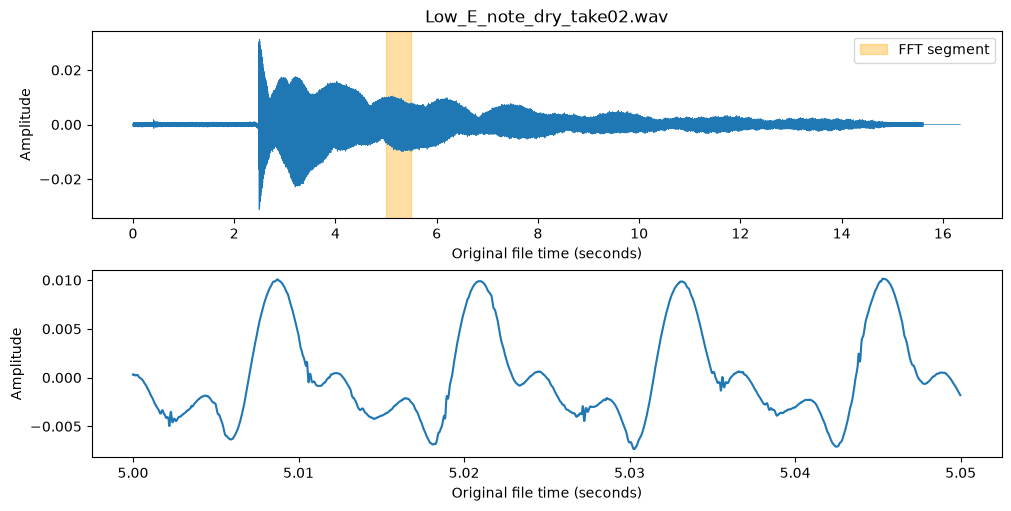

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), constrained_layout=True)
axes[0].plot(np.arange(len(signal)) / sample_rate, signal, linewidth=0.5)
axes[0].axvspan(start_sample / sample_rate, stop_sample / sample_rate,
                color="orange", alpha=0.35, label="FFT segment")
axes[0].set(title=file_path.name, xlabel="Original file time (seconds)", ylabel="Amplitude")
axes[0].legend()
zoom_count = min(sample_count, round(0.05 * sample_rate))
axes[1].plot((start_sample + np.arange(zoom_count)) / sample_rate, segment[:zoom_count])
axes[1].set(xlabel="Original file time (seconds)", ylabel="Amplitude")
plt.show()


## 3. Turn the segment into a frequency spectrum
Imagine comparing the waveform with repeating waves at different frequencies.
The FFT computes those comparisons efficiently.

- Subtract the mean to remove a constant offset (DC), which is not vibration.
- Multiply by a **Hann window**: gently taper the segment's edges toward zero.
  This reduces spectral spreading caused by abruptly cutting the waveform.
  It also broadens peaks; it does not magically increase frequency resolution.
- `rfft` returns complex coefficients; `abs` gives their magnitudes.
- `rfftfreq` labels the coefficients in Hz using the sample spacing `1 / sample_rate`.

Bin spacing = sample_rate / sample_count = 1 / duration.
For 22,050 samples at 44,100 Hz, the frequency grid is 0, 2, 4, ... 22,050 Hz.
**2 Hz is the grid spacing, not a guaranteed pitch accuracy.** A half-second
window is useful for this sustained-note lesson but can mix several fast notes.
Magnitudes below are uncalibrated FFT values, not RMS, loudness, or probabilities.


In [3]:
centered = segment - np.mean(segment)
window = np.hanning(sample_count)
windowed = centered * window
spectrum = np.fft.rfft(windowed)
magnitudes = np.abs(spectrum)
frequencies = np.fft.rfftfreq(sample_count, d=1 / sample_rate)
bin_spacing = sample_rate / sample_count

# Skip the zero-frequency bin. This finds a dominant component, not necessarily pitch.
if not np.any(magnitudes[1:] > 0):
    raise ValueError("This segment has no varying signal to analyze.")
peak_index = 1 + np.argmax(magnitudes[1:])
dominant_frequency = frequencies[peak_index]
print(f"FFT grid spacing: {bin_spacing:.2f} Hz")
print(f"Strongest nonzero frequency bin: {dominant_frequency:.2f} Hz")
print("A strongest bin alone does not establish the fundamental or even that a note is present.")


FFT grid spacing: 2.00 Hz
Strongest nonzero frequency bin: 82.00 Hz
A strongest bin alone does not establish the fundamental or even that a note is present.


## 4. Read the spectrum before calling it a pitch
For a pitched string, the fundamental is the base repetition frequency;
harmonics appear approximately at 2×, 3×, 4× that frequency. One guitar note
can therefore make many peaks. A stronger second harmonic can make a simple
largest-peak detector report an octave too high.

This low-E take's 3.0–3.5 s example has its largest bin at **164 Hz**, with a
lower peak near **82 Hz**. That pattern is consistent with low E and a stronger
second harmonic; it is not two automatically identified notes. The code never
uses the filename or an expected E frequency to choose its largest peak.

The graph zooms to 0–1,000 Hz for readability; the calculation searched all
nonzero bins. The y-axis is relative to this segment's maximum, so do not use
it to compare recording volumes. Original audio is never changed.


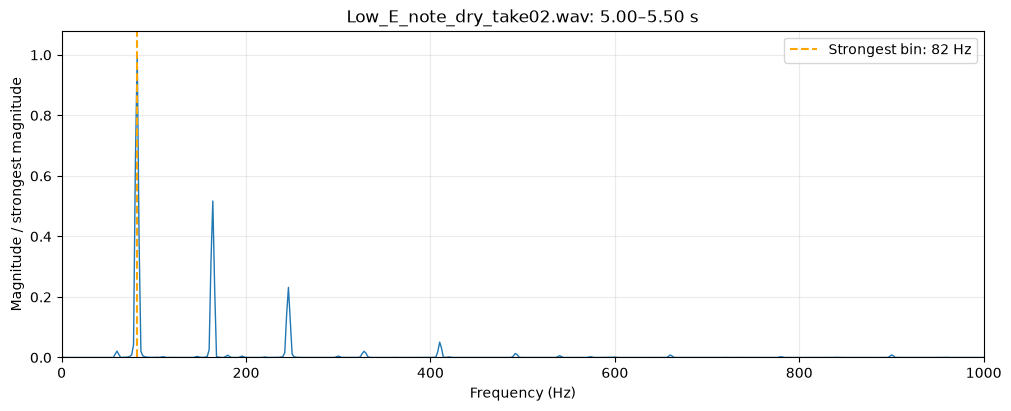

In [4]:
relative_magnitude = magnitudes / magnitudes[peak_index]
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(frequencies, relative_magnitude, linewidth=1)
ax.set(xlim=(0, 1000), ylim=(0, 1.08), xlabel="Frequency (Hz)",
       ylabel="Magnitude / strongest magnitude",
       title=f"{file_path.name}: {start_sample / sample_rate:.2f}–{stop_sample / sample_rate:.2f} s")
if dominant_frequency <= 1000:
    ax.axvline(dominant_frequency, color="orange", linestyle="--",
               label=f"Strongest bin: {dominant_frequency:.0f} Hz")
    ax.legend()
ax.grid(alpha=0.25)
plt.show()


## Compare the spectra
Change only `file_path` to `data/raw/Low_E_note_dry_take01.wav`, then rerun
all cells. In that take, this segment's strongest bin is about **82 Hz**.
The two takes illustrate why largest peak ≠ reliable fundamental detector.
Try A take01 next; its strongest bin is around **110 Hz** in this interval.
These are inspection examples, not held-out evaluation or tuning targets.

Continue below to compare these spectra with a repetition-based estimate.

API references: [NumPy rfft](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html),
[rfftfreq](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfftfreq.html),
[Hann window](https://numpy.org/doc/stable/reference/generated/numpy.hanning.html).


## 5. Measure similarity at different sample shifts (autocorrelation)
A **lag** is a shift measured in samples. At lag 538, compare sample 0 with
sample 538, sample 1 with sample 539, and so on. Python expresses those two
overlapping pieces as `centered[:-538]` and `centered[538:]`.

Multiply matching samples and add the products: matching signs contribute
positively, opposite signs negatively. Repeating shapes produce a high sum.
At lag zero the waveform matches itself perfectly, so that cannot tell us its
period. We divide every sum by that zero-lag sum to put the score on a common
scale. A score near 1 means strong similarity, **not a probability of correctness**.

Formula: score(k) = sum(x[i] * x[i+k]) / sum(x[i] ** 2), using the overlapping
samples in the numerator. Larger shifts have fewer overlapping pairs, so this
simple score somewhat favors shorter shifts. We do not pad or wrap the audio.
Use the mean-centered segment, without the FFT's Hann taper: here we want to
compare its repeating shape without adding that extra amplitude envelope.

Search settings are **60–1,000 Hz**, an explicit range for this single-note
exercise: below standard low E to above our current notes. It is not the whole
guitar range, especially with alternate tunings/high frets. Faster repetition
means fewer samples: minimum lag = ceil(sample_rate / 1,000), maximum lag =
floor(sample_rate / 60). At 44,100 Hz those are 45–735 samples. No expected
frequency from a filename enters the calculation.

We choose the highest positive **local peak** inside that range, rather than
a near-zero shift where neighboring samples naturally resemble each other.
This is a baseline: harmonics and multiple-period matches can still cause
octave errors. Noise can also make positive peaks. There is no voiced/unvoiced
decision, confidence threshold, or sub-sample interpolation yet.


In [5]:
minimum_frequency = 60.0
maximum_frequency = 1000.0
if not 0 < minimum_frequency < maximum_frequency < sample_rate / 2:
    raise ValueError("Choose positive frequency bounds below half the sample rate.")
minimum_lag = int(np.ceil(sample_rate / maximum_frequency))
maximum_lag = int(np.floor(sample_rate / minimum_frequency))
if minimum_lag > maximum_lag or len(centered) <= 2 * maximum_lag:
    raise ValueError("Use a longer segment or a valid narrower frequency range.")

zero_lag_sum = np.sum(centered ** 2)
if not np.isfinite(zero_lag_sum) or zero_lag_sum <= 0:
    raise ValueError("No varying signal: a constant or silent segment has no measurable period.")

# One extra lag lets us check both neighbors of a peak at the search boundary.
lags = np.arange(maximum_lag + 2)
similarity = np.empty(len(lags))
similarity[0] = 1.0
for lag in lags[1:]:
    earlier = centered[:-lag]
    later = centered[lag:]
    sum_of_products = np.sum(earlier * later)
    similarity[lag] = sum_of_products / zero_lag_sum

peak_lags = []
for lag in range(minimum_lag, maximum_lag + 1):
    if (similarity[lag] > 0
            and similarity[lag] > similarity[lag - 1]
            and similarity[lag] >= similarity[lag + 1]):
        peak_lags.append(lag)
peak_lags = np.array(peak_lags, dtype=int)
if len(peak_lags) == 0:
    raise ValueError("No positive local peak in this range; no candidate period reported.")

best_lag = int(peak_lags[np.argmax(similarity[peak_lags])])
period_seconds = best_lag / sample_rate
candidate_frequency = sample_rate / best_lag
print(f"Searched shifts: {minimum_lag}–{maximum_lag} samples")
print(f"Best candidate shift: {best_lag} samples")
print(f"Period: {best_lag} / {sample_rate} = {period_seconds:.6f} seconds")
print(f"Candidate fundamental: {sample_rate} / {best_lag} = {candidate_frequency:.2f} Hz")
print(f"Similarity: {similarity[best_lag]:.3f} (not a confidence probability)")
print(f"For comparison, strongest FFT bin: {dominant_frequency:.2f} Hz")
print("Strongest local candidates (lag, frequency, similarity):")
ranked_lags = peak_lags[np.argsort(similarity[peak_lags])[::-1]]
for lag in ranked_lags[:5]:
    print(f"  {lag:4d} samples   {sample_rate / lag:7.2f} Hz   {similarity[lag]:.3f}")


Searched shifts: 45–735 samples
Best candidate shift: 539 samples
Period: 539 / 44100 = 0.012222 seconds
Candidate fundamental: 44100 / 539 = 81.82 Hz
Similarity: 0.976 (not a confidence probability)
For comparison, strongest FFT bin: 82.00 Hz
Strongest local candidates (lag, frequency, similarity):
   539 samples     81.82 Hz   0.976


## 6. Inspect the candidate, rather than accepting just a number
The top graph shows similarity versus sample shift. The shaded range is what
we searched; zero lag is excluded. Orange dots show competing positive local
peaks, including possible matches at fractions or multiples of the true period.

The bottom graph overlays the segment with samples taken `best_lag` positions
later. Its x-axis is relative to the selected segment; the shifted trace's
original indices are start_sample + best_lag + the plotted offsets. We show
three candidate periods so the plot remains readable. Both traces keep their
original amplitude scale (after mean subtraction); no separate scaling is used.


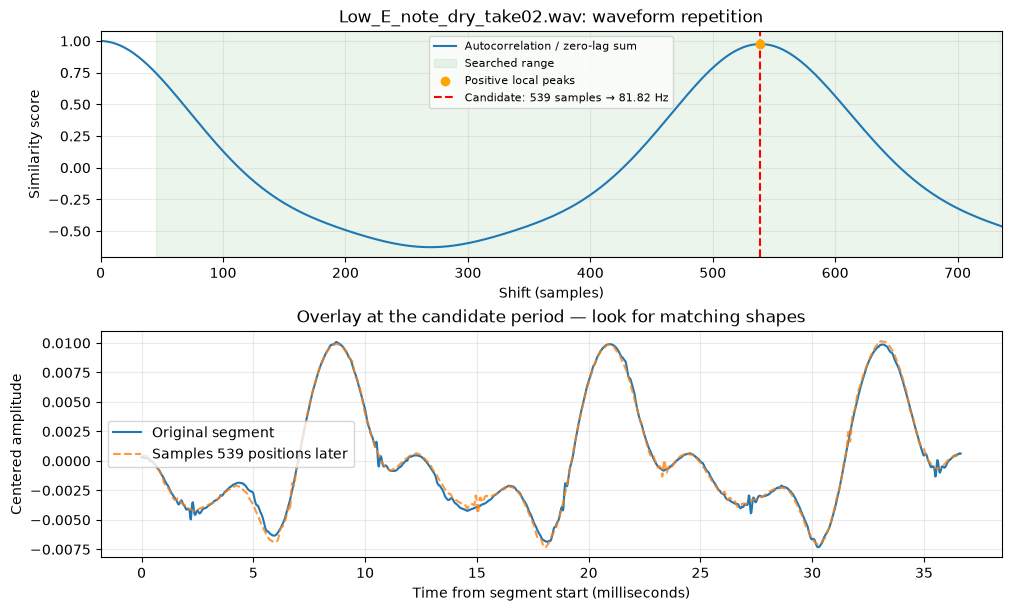

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), constrained_layout=True)
axes[0].plot(lags, similarity, label="Autocorrelation / zero-lag sum")
axes[0].axvspan(minimum_lag, maximum_lag, color="green", alpha=0.08,
                label="Searched range")
axes[0].scatter(peak_lags, similarity[peak_lags], color="orange", zorder=3,
                label="Positive local peaks")
axes[0].axvline(best_lag, color="red", linestyle="--",
                label=f"Candidate: {best_lag} samples → {candidate_frequency:.2f} Hz")
axes[0].set(xlabel="Shift (samples)", ylabel="Similarity score",
            title=f"{file_path.name}: waveform repetition", xlim=(0, maximum_lag + 1))
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

overlay_count = min(3 * best_lag, len(centered) - best_lag)
overlay_time = np.arange(overlay_count) / sample_rate * 1000
axes[1].plot(overlay_time, centered[:overlay_count], label="Original segment")
axes[1].plot(overlay_time, centered[best_lag:best_lag + overlay_count],
             linestyle="--", alpha=0.8, label=f"Samples {best_lag} positions later")
axes[1].set(xlabel="Time from segment start (milliseconds)", ylabel="Centered amplitude",
            title="Overlay at the candidate period — look for matching shapes")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.show()


## Compare takes with unchanged settings
Change `file_path` in section 1 and rerun all cells. On the existing 3.0–3.5 s
segments, both low-E takes select lag 538 (81.97 Hz), both C takes select lag
168 (262.50 Hz), and the A takes select lags 399/400 (110.53/110.25 Hz).
Those results are consistent with the recording labels, not independent proof
of accuracy. Integer-lag estimates and their printed decimals are not exact
tuning measurements. We have already inspected these recordings; fresh takes
or a known new melody are needed for further evaluation.

Stop here to inspect the competing peaks and overlay. Next, examine whether
this estimate stays consistent across several ringing segments, then shorten
and slide the window for a known melody. Chords require a later multipitch
method: one selected lag does not decode several simultaneous notes.

Definition reference: [NumPy correlation documentation](https://numpy.org/doc/stable/reference/generated/numpy.correlate.html).
We write the overlapping products explicitly instead of hiding them in a call.
